<a href="https://colab.research.google.com/github/sigma-asif/ml-core-intuition/blob/main/4.KNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# K-Nearest Neighbors (KNN) Classification

## Problem Statement

The objective of this project is to implement the K-Nearest Neighbors (KNN) algorithm to classify students into two categories: Pass or Fail.

We will use two features:
- Study Hours
- Exam Marks

Based on these features, the algorithm will predict whether a new student will Pass or Fail.

We will use Euclidean Distance to measure the distance between data points and Majority Voting to determine the final predicted class.

In this implementation, K = 3.

The KNN algorithm will be implemented from scratch using Python without using the built-in KNN classifier from Scikit-learn.



## Step 2: Import Required Libraries


In [1]:

import numpy as np
import matplotlib.pyplot as plt



## Step 3: Create the Dataset

In this step, we create a small student dataset.

Each student has two features:
- Study Hours (X1)
- Exam Marks (X2)

The target variable represents the student's result:
- 0 = Fail
- 1 = Pass

We will use this dataset to train our KNN model and predict the class of a new student.


In [2]:

# Features: [Study Hours, Exam Marks]

X = np.array([
    [1, 20],
    [2, 30],
    [3, 40],
    [6, 70],
    [7, 80],
    [8, 90]
])

# Target labels
# 0 = Fail, 1 = Pass

y = np.array([0, 0, 0, 1, 1, 1])

print("Features (X):")
print(X)

print("\nTarget Labels (y):")
print(y)


Features (X):
[[ 1 20]
 [ 2 30]
 [ 3 40]
 [ 6 70]
 [ 7 80]
 [ 8 90]]

Target Labels (y):
[0 0 0 1 1 1]



## Step 4: Visualize the Dataset

In this step, we visualize the student dataset using a scatter plot.




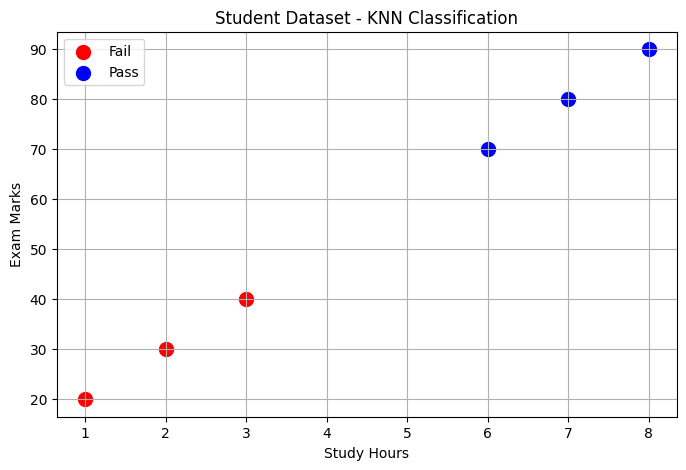

In [3]:

plt.figure(figsize=(8, 5))

plt.scatter(X[y == 0, 0], X[y == 0, 1],
            color='red', label='Fail', s=100)

plt.scatter(X[y == 1, 0], X[y == 1, 1],
            color='blue', label='Pass', s=100)

plt.xlabel("Study Hours")
plt.ylabel("Exam Marks")
plt.title("Student Dataset - KNN Classification")

plt.legend()
plt.grid(True)
plt.show()



## Step 5: Define the Euclidean Distance Function

KNN uses distance to identify the nearest neighbors.

In this implementation, we use Euclidean Distance.

Formula:

d = sqrt((x2 - x1)^2 + (y2 - y1)^2)

Where:
- x1, y1 = Coordinates of the first data point.
- x2, y2 = Coordinates of the second data point.
- d = Euclidean distance between two points.

This function calculates the distance between a new student and an existing student.


In [4]:

def euclidean_distance(point1, point2):

    distance = np.sqrt(np.sum((point1 - point2) ** 2))

    return distance


In [5]:

new_student = np.array([5, 60])

student_A = X[0]

distance = euclidean_distance(new_student, student_A)

print("Distance from Student A:", distance)


Distance from Student A: 40.19950248448356



## Step 6: Calculate Distance from All Data Points

In this step, we calculate the Euclidean distance between the new student and every student in the existing dataset.

The new student's features are:

Study Hours = 5
Exam Marks = 60

We calculate six distances because our dataset contains six students.

These distances will help us identify the nearest neighbors.


In [6]:

new_student = np.array([5, 60])

distances = []

for i in range(len(X)):

    distance = euclidean_distance(new_student, X[i])

    distances.append(distance)

    print(f"Student {chr(65+i)}: Distance = {distance:.2f}")


Student A: Distance = 40.20
Student B: Distance = 30.15
Student C: Distance = 20.10
Student D: Distance = 10.05
Student E: Distance = 20.10
Student F: Distance = 30.15



## Step 7: Find the K Nearest Neighbors

In this step, we select the K nearest data points based on their calculated distances.

We set:

K = 3

This means we select the three students having the smallest distances from the new student.

We use NumPy's argsort() function to sort the distance indices in ascending order.

The first three indices represent the nearest neighbors.


In [7]:

K = 3

# Sort distances in ascending order
sorted_indices = np.argsort(distances)

# Select the first K indices
nearest_indices = sorted_indices[:K]

print("Nearest Neighbor Indices:", nearest_indices)

print("\nNearest Neighbors:")

for index in nearest_indices:

    print(
        f"Student {chr(65+index)} | "
        f"Distance: {distances[index]:.2f} | "
        f"Class: {y[index]}"
    )


Nearest Neighbor Indices: [3 2 4]

Nearest Neighbors:
Student D | Distance: 10.05 | Class: 1
Student C | Distance: 20.10 | Class: 0
Student E | Distance: 20.10 | Class: 1



## Step 8: Apply Majority Voting

After finding the K nearest neighbors, we collect their class labels.

K = 3

The nearest neighbors have the following labels:

Student D = Pass (1)
Student C = Fail (0)
Student E = Pass (1)

KNN uses Majority Voting to determine the final class.

The class receiving the highest number of votes becomes the predicted class.


In [8]:

# Get the labels of nearest neighbors

nearest_labels = y[nearest_indices]

# Count votes for each class
votes = np.bincount(nearest_labels)

# Select the class with the highest votes
predicted_class = np.argmax(votes)

print("Nearest Neighbor Labels:", nearest_labels)

print("Fail Votes:", votes[0])
print("Pass Votes:", votes[1])

print("Predicted Class:", predicted_class)


Nearest Neighbor Labels: [1 0 1]
Fail Votes: 1
Pass Votes: 2
Predicted Class: 1



## Step 9: Display the Final Prediction

In this step, we display the final prediction.

The predicted class is determined using Majority Voting.

- 0 represents Fail.
- 1 represents Pass.

We convert the numerical prediction into a readable class name.


In [9]:

if predicted_class == 1:
    result = "PASS"
else:
    result = "FAIL"

print("New Student Information:")
print("Study Hours:", new_student[0])
print("Exam Marks:", new_student[1])

print("\nFinal Prediction:", result)


New Student Information:
Study Hours: 5
Exam Marks: 60

Final Prediction: PASS
